# Applied Vision Transformer: Swin-T on HAM10000
**Youssef Hajri, Student ID 1425158, MAAI901 Deep Learning for Visual Data (Assessment 2)**

In this notebook I fine-tune a Swin Transformer (Swin-T) to classify dermoscopic images of skin lesions into the seven HAM10000 classes. I compare two pretraining sources (ImageNet-22k and ImageNet-1k), report metrics that expose minority-class performance, and check for bias across a skin-tone proxy and across how the diagnosis was confirmed.

**Data:** ISIC 2018 Task 3 training set (= HAM10000, 10,015 images) plus the official lesion groupings file.
**Weights:** official Swin-T checkpoints released by the Swin authors (GitHub release `SwinTransformer/storage`).
**Training strategy:** partial fine-tuning of the final stage (explained in Section 4).

In [1]:
import os, json, time, math, random
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import timm
from timm.models.swin_transformer import checkpoint_filter_fn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image

DATA = os.environ.get('DATA_DIR', 'data')
OUT = os.environ.get('OUT_DIR', 'outputs'); os.makedirs(OUT, exist_ok=True)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count())
CLASSES = ['MEL','NV','BCC','AKIEC','BKL','DF','VASC']
NAMES = ['Melanoma','Naevus','Basal cell carc.','Actinic keratosis','Benign keratosis','Dermatofibroma','Vascular']
MALIGNANT = [0, 2, 3]  # mel, bcc, akiec
NAVY, TEAL, ORANGE, GREEN, ICE = '#14213D', '#1F6F8B', '#E76F51', '#2A9D8F', '#8FB8C9'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print(torch.__version__, timm.__version__)

/tmp/claude-0/-home-claude/303a2548-78ee-501b-84f8-76c622ce8da7/scratchpad/vit/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.14.1+cu130 1.0.30


## 1. Data and pre-processing
* **Lesion-level split.** HAM10000 has 10,015 images of 7,470 lesions, and some lesions were photographed several times. I use `StratifiedGroupKFold` with `lesion_id` as the group so no lesion appears in more than one split (70/15/15).
* **Resizing.** Shorter side to 224 px (bicubic), then a 224x224 centre crop, matching the Swin-T input size.
* **Normalisation.** ImageNet mean and standard deviation, as expected by the pretrained weights.
* **No colour constancy.** I deliberately avoid colour normalisation because skin tone is one of the things I want to analyse.
* **Skin-tone proxy.** HAM10000 has no skin-type labels, so I estimate the Individual Typology Angle (ITA) from the border ring of each image (outer 15%, ignoring dark vignetting): ITA = arctan((L* - 50) / b*). This is only a rough proxy.

In [2]:
from sklearn.model_selection import StratifiedGroupKFold
from skimage import color
from concurrent.futures import ProcessPoolExecutor

def load_image(name):
    im = Image.open(f'{DATA}/ISIC2018_Task3_Training_Input/{name}.jpg').convert('RGB')
    w, h = im.size; s = 224 / min(w, h)
    im = im.resize((round(w*s), round(h*s)), Image.BICUBIC)
    w, h = im.size; l, t = (w-224)//2, (h-224)//2
    arr = np.asarray(im.crop((l, t, l+224, t+224)), dtype=np.uint8)
    lab = color.rgb2lab(arr / 255.0)
    m = np.ones((224, 224), bool); b = 34; m[b:-b, b:-b] = False
    L, B = lab[..., 0][m], lab[..., 2][m]
    keep = L > 25
    if keep.sum() > 200: L, B = L[keep], B[keep]
    ita = np.degrees(np.arctan((np.median(L) - 50) / max(np.median(B), 1e-3)))
    return arr, ita

if os.path.exists(f'{DATA}/X224.npy') and os.path.exists(f'{DATA}/meta.csv'):
    X = np.load(f'{DATA}/X224.npy'); meta = pd.read_csv(f'{DATA}/meta.csv')
else:
    gt = pd.read_csv(f'{DATA}/ISIC2018_Task3_Training_GroundTruth/ISIC2018_Task3_Training_GroundTruth.csv')
    gt['label'] = gt[CLASSES].values.argmax(1)
    meta = gt[['image','label']].merge(pd.read_csv(f'{DATA}/groupings.csv'), on='image')
    sgk = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
    fold = np.zeros(len(meta), int)
    for k, (_, te) in enumerate(sgk.split(meta, meta.label, meta.lesion_id)): fold[te] = k
    meta['split'] = np.where(fold < 14, 'train', np.where(fold < 17, 'val', 'test'))
    with ProcessPoolExecutor(4) as ex: res = list(ex.map(load_image, meta.image, chunksize=64))
    X = np.stack([r[0] for r in res]); meta['ita'] = [r[1] for r in res]
    np.save(f'{DATA}/X224.npy', X); meta.to_csv(f'{DATA}/meta.csv', index=False)

meta['tone'] = pd.cut(meta.ita, [-90, 41, 55, 90], labels=['Darker (ITA<=41)', 'Light (41-55)', 'Very light (>55)'])
assert meta.groupby('lesion_id').split.nunique().max() == 1  # no lesion leakage
if os.environ.get('SMOKE'):  # quick test mode
    sel = meta.groupby(['split', 'label']).head(8).index.values; X = X[sel]; meta = meta.loc[sel].reset_index(drop=True)
print(X.shape); print(pd.crosstab(meta.split, meta.label.map(dict(enumerate(CLASSES)))))

(10015, 224, 224, 3)
label  AKIEC  BCC  BKL  DF  MEL    NV  VASC
split                                      
test      48   76  165  17  167  1006    21
train    231  362  769  81  780  4692   100
val       48   76  165  17  166  1007    21


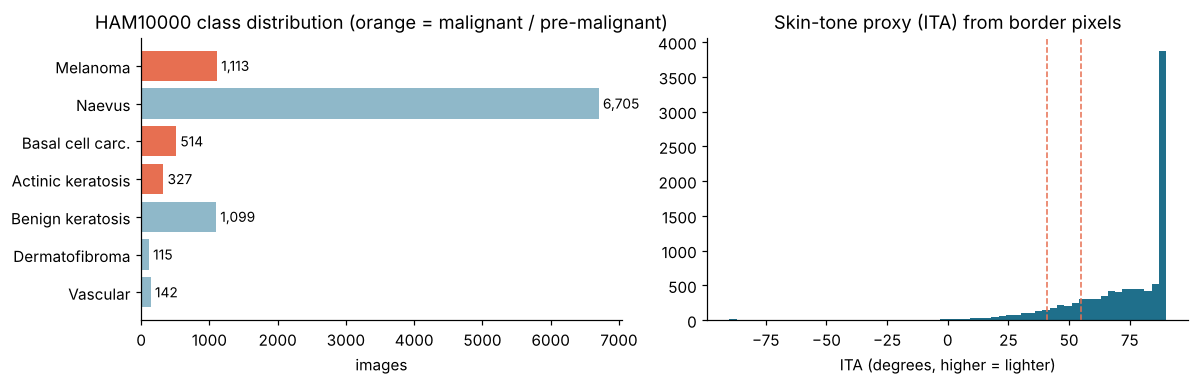

tone
Very light (>55)    8129
Light (41-55)        991
Darker (ITA<=41)     895
Name: count, dtype: int64


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cnt = meta.label.value_counts().sort_index()
cols = [ORANGE if i in MALIGNANT else ICE for i in range(7)]
ax[0].barh(NAMES[::-1], cnt.values[::-1], color=cols[::-1])
for i, v in enumerate(cnt.values[::-1]): ax[0].text(v + 60, i, f'{v:,}', va='center', fontsize=9)
ax[0].set_title('HAM10000 class distribution (orange = malignant / pre-malignant)'); ax[0].set_xlabel('images')
ax[1].hist(meta.ita, bins=60, color=TEAL)
for x in (41, 55): ax[1].axvline(x, color=ORANGE, ls='--', lw=1)
ax[1].set_title('Skin-tone proxy (ITA) from border pixels'); ax[1].set_xlabel('ITA (degrees, higher = lighter)')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_data.png'); plt.show()
print(meta.tone.value_counts())

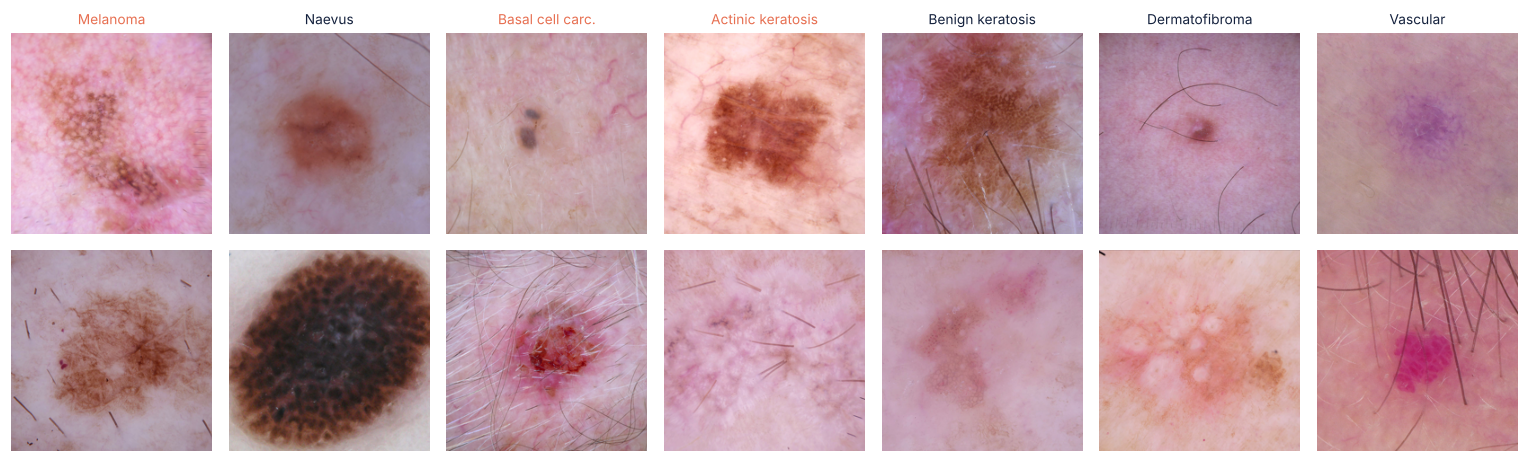

In [4]:
fig, axes = plt.subplots(2, 7, figsize=(14, 4.4))
rng = np.random.default_rng(1)
for c in range(7):
    idx = rng.choice(np.where(meta.label == c)[0], 2, replace=False)
    for r in range(2):
        axes[r, c].imshow(X[idx[r]]); axes[r, c].axis('off')
    axes[0, c].set_title(NAMES[c], fontsize=9, color=ORANGE if c in MALIGNANT else NAVY)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_samples.png'); plt.show()

## 2. Model selection and configuration
I use **Swin-T** (Liu et al., 2021): 28M parameters, 4.5 GFLOPs, a hierarchical transformer with shifted-window attention. I chose it over a plain ViT because window attention reintroduces locality, which suits a dataset of only ~10k images, and because Swin has already been applied to dermoscopy (Ayas, 2023).

I compare two official checkpoints with the **same architecture**: ImageNet-22k pretraining and ImageNet-1k pretraining. This isolates the effect of pretraining scale, the confound I identified in my Week 6 paper.

The ImageNet classifier is replaced by a new 7-way linear head.

In [5]:
def build(ckpt):
    m = timm.create_model('swin_tiny_patch4_window7_224', pretrained=False, num_classes=7, drop_path_rate=0.1)
    sd = checkpoint_filter_fn(torch.load(f'{DATA}/{ckpt}', map_location='cpu'), m)
    sd = {k: v for k, v in sd.items() if not k.startswith('head')}
    print(ckpt, m.load_state_dict(sd, strict=False))
    return m

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1,3,1,1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1,3,1,1)
def to_tensor(xb): return (torch.from_numpy(xb).permute(0,3,1,2).float() / 255 - MEAN) / STD

@torch.no_grad()
def cache_stage3(m, bs=64):
    # Output of the first three stages (frozen): (N, 14, 14, 384), stored in fp16
    m.eval(); out = []
    for i in range(0, len(X), bs):
        h = m.patch_embed(to_tensor(X[i:i+bs]))
        for s in range(3): h = m.layers[s](h)
        out.append(h.half())
    return torch.cat(out)

## 3. Training / fine-tuning process
I use **partial fine-tuning**, which keeps the general low-level features from pretraining and adapts the high-level ones: stages 1 to 3 are frozen and their output is computed once and cached; **stage 4, the final norm and the new head are trained**. Stage 4 holds 14M of the 28M parameters, so this is a substantial adaptation, not just a linear probe.

* Loss: class-weighted cross-entropy (inverse class frequency), to counter the imbalance.
* Optimiser: AdamW, weight decay 0.05; learning rate 1e-4 for stage 4 and 1e-3 for the head; cosine decay.
* Augmentation: random horizontal/vertical flips and 90-degree rotations applied to the cached 14x14 feature grid (a cheap feature-space version of the usual geometric augmentation; lesions have no fixed orientation).
* 8 epochs, batch 64; the epoch with the best **validation balanced accuracy** is kept.
* A **linear probe** (frozen features + logistic regression) is reported as a baseline.

In [6]:
y = torch.tensor(meta.label.values)
tr, va, te = [np.where(meta.split == s)[0] for s in ('train', 'val', 'test')]
counts = np.bincount(meta.label.values[tr], minlength=7)
cw = torch.tensor(counts.sum() / (7 * counts), dtype=torch.float32)

def head_forward(m, h):
    h = m.layers[3](h.float()); h = m.norm(h)
    return m.head(h)

def aug(h):
    if random.random() < .5: h = h.flip(1)
    if random.random() < .5: h = h.flip(2)
    return torch.rot90(h, random.randint(0, 3), dims=(1, 2))

@torch.no_grad()
def predict(m, H, idx, bs=256):
    m.eval(); return torch.cat([F.softmax(head_forward(m, H[idx[i:i+bs]]), 1) for i in range(0, len(idx), bs)]).numpy()

@torch.no_grad()
def embed(m, H, idx, bs=256):
    m.eval(); out = []
    for i in range(0, len(idx), bs):
        h = m.norm(m.layers[3](H[idx[i:i+bs]].float())); out.append(h.mean((1, 2)))
    return torch.cat(out).numpy()

def train(m, H, epochs=int(os.environ.get('EPOCHS', 8)), bs=64):
    for p in m.parameters(): p.requires_grad = False
    params = [{'params': m.layers[3].parameters(), 'lr': 1e-4}, {'params': list(m.norm.parameters()) + list(m.head.parameters()), 'lr': 1e-3}]
    for g in params:
        for p in g['params']: p.requires_grad = True
    opt = torch.optim.AdamW(params, weight_decay=0.05)
    steps = epochs * math.ceil(len(tr) / bs); sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[1e-4, 1e-3], total_steps=steps, pct_start=0.1, anneal_strategy='cos')
    hist, best, best_state = [], -1, None
    for ep in range(epochs):
        m.train(); perm = np.random.permutation(tr); tl = 0; t0 = time.time()
        for i in range(0, len(perm), bs):
            b = perm[i:i+bs]
            loss = F.cross_entropy(head_forward(m, aug(H[b])), y[b], weight=cw)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tl += loss.item() * len(b)
        pv = predict(m, H, va)
        vl = F.cross_entropy(torch.log(torch.tensor(pv) + 1e-9).float(), y[va], weight=cw).item()
        vb = balanced_accuracy_score(y[va], pv.argmax(1))
        hist.append(dict(epoch=ep + 1, train_loss=tl / len(tr), val_loss=vl, val_bacc=vb))
        print(f'epoch {ep+1}: train loss {tl/len(tr):.3f}  val loss {vl:.3f}  val bal.acc {vb:.3f}  ({time.time()-t0:.0f}s)')
        if vb > best: best, best_state = vb, {k: v.clone() for k, v in m.state_dict().items()}
    m.load_state_dict(best_state)
    return pd.DataFrame(hist)

In [7]:
RUNS = {}
for name, ckpt in [('Swin-T (ImageNet-22k)', 'swin_22k.pth'), ('Swin-T (ImageNet-1k)', 'swin_1k.pth')]:
    t0 = time.time(); m = build(ckpt); H = cache_stage3(m); print(f'cached {tuple(H.shape)} in {time.time()-t0:.0f}s')
    # linear probe baseline on frozen features (before any fine-tuning)
    Etr, Ete = embed(m, H, tr), embed(m, H, te)
    lp = LogisticRegression(max_iter=3000, class_weight='balanced', C=1.0).fit(Etr, y[tr].numpy())
    p_lp = lp.predict_proba(Ete)
    hist = train(m, H)
    RUNS[name] = dict(hist=hist, p_test=predict(m, H, te), p_val=predict(m, H, va), p_lp=p_lp, emb_test=embed(m, H, te))
    tag = '22k' if '22k' in name else '1k'
    np.savez(f'{OUT}/pred_{tag}.npz', p_test=RUNS[name]['p_test'], p_lp=p_lp, te=te); hist.to_csv(f'{OUT}/hist_{tag}.csv', index=False)
    del H

swin_22k.pth _IncompatibleKeys(missing_keys=['head.fc.weight', 'head.fc.bias'], unexpected_keys=[])


cached (10015, 14, 14, 384) in 626s


epoch 1: train loss 1.671  val loss 1.273  val bal.acc 0.510  (90s)


epoch 2: train loss 1.072  val loss 1.067  val bal.acc 0.635  (92s)


epoch 3: train loss 0.902  val loss 0.997  val bal.acc 0.637  (88s)


...

epoch 4: train loss 0.971  val loss 1.072  val bal.acc 0.605  (91s)


epoch 5: train loss 0.905  val loss 1.052  val bal.acc 0.609  (97s)


epoch 6: train loss 0.878  val loss 1.046  val bal.acc 0.603  (95s)


epoch 7: train loss 0.853  val loss 1.044  val bal.acc 0.608  (97s)


epoch 8: train loss 0.850  val loss 1.044  val bal.acc 0.614  (96s)


## 4. Evaluation metrics and results
Because of the imbalance, plain accuracy is not enough. I report accuracy (for comparison with the literature), **balanced accuracy** (mean per-class recall), **macro-F1**, **mean recall on the malignant classes** (MEL, BCC, AKIEC), **ROC-AUC for malignant vs benign** using the score P(MEL)+P(BCC)+P(AKIEC), and **expected calibration error (ECE)**. 95% confidence intervals come from a lesion-level bootstrap of the test set (1,000 resamples).

In [8]:
yt = y[te].numpy(); lesions_te = meta.lesion_id.values[te]
def ece(p, t, bins=15):
    conf, pred = p.max(1), p.argmax(1); e = 0
    for lo in np.linspace(0, 1, bins + 1)[:-1]:
        s = (conf > lo) & (conf <= lo + 1 / bins)
        if s.any(): e += s.mean() * abs((pred[s] == t[s]).mean() - conf[s].mean())
    return e
def metrics(p, t):
    pr = p.argmax(1); rec = (confusion_matrix(t, pr, labels=range(7)).diagonal() / np.bincount(t, minlength=7))
    mal = np.isin(t, MALIGNANT).astype(int); score = p[:, MALIGNANT].sum(1)
    return dict(acc=accuracy_score(t, pr), bacc=balanced_accuracy_score(t, pr), macro_f1=f1_score(t, pr, average='macro'),
                mal_recall=np.isin(pr[mal == 1], MALIGNANT).mean(), auc_mal=roc_auc_score(mal, score), ece=ece(p, t))
def boot_ci(p, t, key, n=1000):
    ul = np.unique(lesions_te); idx_by = {l: np.where(lesions_te == l)[0] for l in ul}; r = np.random.default_rng(0); vals = []
    for _ in range(n):
        ii = np.concatenate([idx_by[l] for l in r.choice(ul, len(ul))])
        if len(np.unique(t[ii])) < 7: continue
        vals.append(metrics(p[ii], t[ii])[key])
    return np.percentile(vals, [2.5, 97.5])

rows = []
for name, R in RUNS.items():
    for kind, p in [('Linear probe', R['p_lp']), ('Partial fine-tune', R['p_test'])]:
        mt = metrics(p, yt); lo, hi = boot_ci(p, yt, 'bacc', int(os.environ.get('BOOT', 1000)))
        rows.append(dict(model=name, method=kind, **mt, bacc_lo=lo, bacc_hi=hi))
res = pd.DataFrame(rows); res.round(3)

,model,method,acc,bacc,macro_f1,mal_recall,auc_mal,ece,bacc_lo,bacc_hi
0,Swin-T (ImageNet-22k),Linear probe,0.766,0.673,0.640,0.739,0.904,0.114,0.603,0.736
1,Swin-T (ImageNet-22k),Partial fine-tune,0.687,0.685,0.535,0.784,0.910,0.053,0.611,0.747
2,Swin-T (ImageNet-1k),Linear probe,0.745,0.647,0.606,0.667,0.879,0.117,0.579,0.708
3,Swin-T (ImageNet-1k),Partial fine-tune,0.683,0.675,0.512,0.718,0.886,0.072,0.616,0.723


Best model: Swin-T (ImageNet-22k)
                   precision    recall  f1-score   support

         Melanoma      0.355     0.623     0.452       167
           Naevus      0.956     0.721     0.822      1006
 Basal cell carc.      0.471     0.632     0.539        76
Actinic keratosis      0.395     0.708     0.507        48
 Benign keratosis      0.592     0.545     0.568       165
   Dermatofibroma      0.179     0.706     0.286        17
         Vascular      0.429     0.857     0.571        21

         accuracy                          0.687      1500
        macro avg      0.482     0.685     0.535      1500
     weighted avg      0.791     0.687     0.719      1500



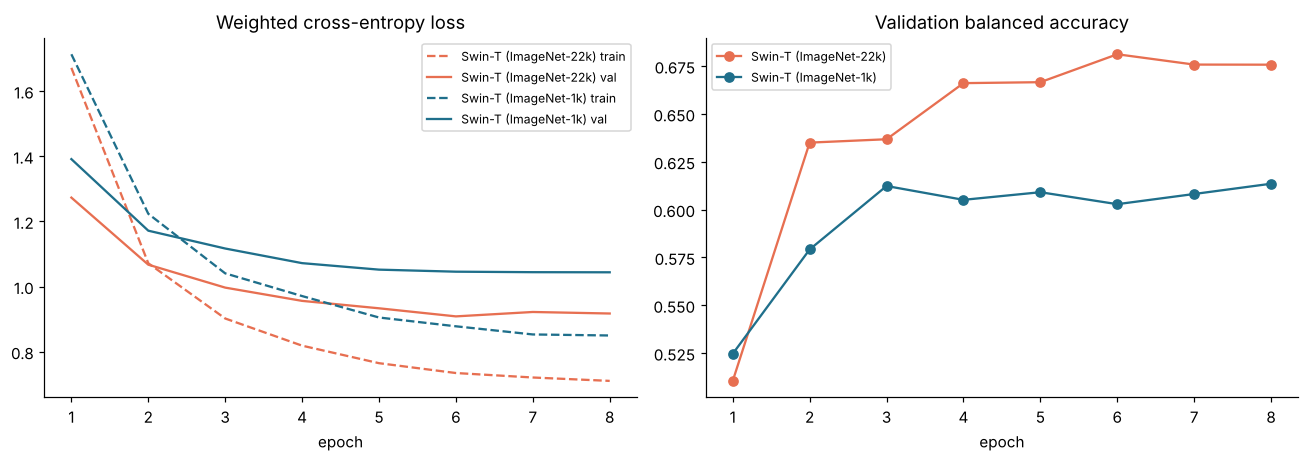

In [9]:
BEST = max(RUNS, key=lambda k: balanced_accuracy_score(yt, RUNS[k]['p_test'].argmax(1)))
P = RUNS[BEST]['p_test']; pred = P.argmax(1); print('Best model:', BEST)
print(classification_report(yt, pred, target_names=NAMES, digits=3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for name, R in RUNS.items():
    h = R['hist']; c = ORANGE if '22k' in name else TEAL
    ax[0].plot(h.epoch, h.train_loss, c=c, ls='--', label=f'{name} train'); ax[0].plot(h.epoch, h.val_loss, c=c, label=f'{name} val')
    ax[1].plot(h.epoch, h.val_bacc, c=c, marker='o', label=name)
ax[0].set_title('Weighted cross-entropy loss'); ax[0].set_xlabel('epoch'); ax[0].legend(fontsize=8)
ax[1].set_title('Validation balanced accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_training.png'); plt.show()

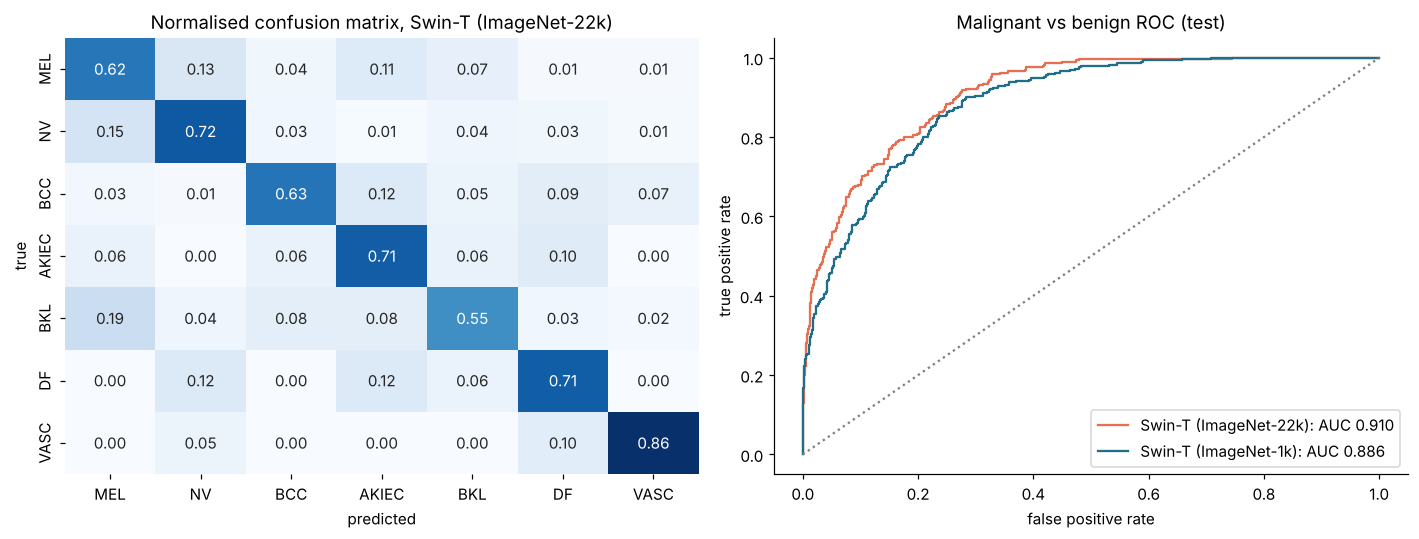

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(yt, pred, normalize='true')
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False)
ax[0].set_title(f'Normalised confusion matrix, {BEST}'); ax[0].set_xlabel('predicted'); ax[0].set_ylabel('true')
for name, R in RUNS.items():
    s = R['p_test'][:, MALIGNANT].sum(1); fpr, tpr, _ = roc_curve(np.isin(yt, MALIGNANT), s)
    ax[1].plot(fpr, tpr, c=ORANGE if '22k' in name else TEAL, label=f'{name}: AUC {roc_auc_score(np.isin(yt, MALIGNANT), s):.3f}')
ax[1].plot([0, 1], [0, 1], c='grey', ls=':'); ax[1].set_title('Malignant vs benign ROC (test)'); ax[1].set_xlabel('false positive rate'); ax[1].set_ylabel('true positive rate'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/fig_cm_roc.png'); plt.show()

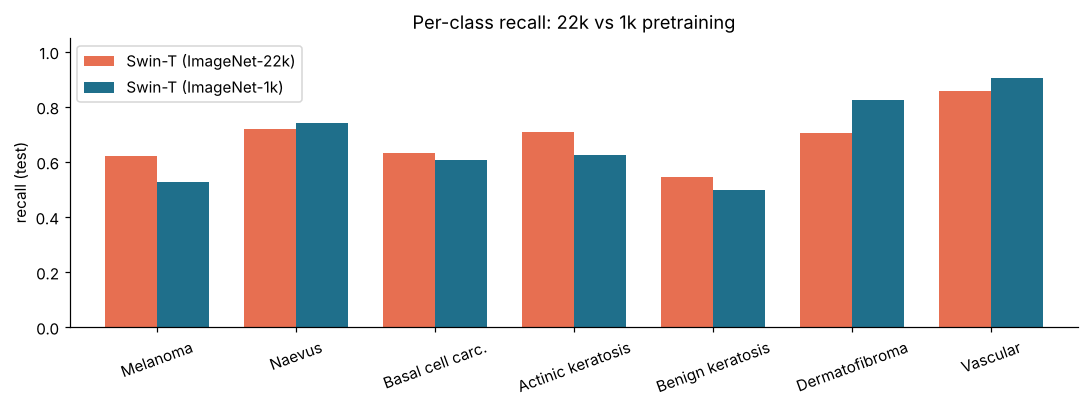

,Swin-T (ImageNet-22k),Swin-T (ImageNet-1k)
Melanoma,0.623,0.527
Naevus,0.721,0.742
Basal cell carc.,0.632,0.605
Actinic keratosis,0.708,0.625
Benign keratosis,0.545,0.497
Dermatofibroma,0.706,0.824
Vascular,0.857,0.905


In [11]:
rec = pd.DataFrame({name: confusion_matrix(yt, R['p_test'].argmax(1), labels=range(7)).diagonal() / np.bincount(yt, minlength=7) for name, R in RUNS.items()}, index=NAMES)
ax = rec.plot.bar(figsize=(10, 3.8), color=[ORANGE, TEAL], width=0.75)
ax.set_ylabel('recall (test)'); ax.set_title('Per-class recall: 22k vs 1k pretraining'); ax.set_ylim(0, 1.05); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_recall.png'); plt.show(); rec.round(3)

## 5. Bias analysis
I look at two possible sources of bias in the best model:
1. **Skin-tone proxy (ITA group).** The dataset is overwhelmingly light-skinned, so I compare performance between the very light, light and darker groups.
2. **How the diagnosis was confirmed.** Histopathology-confirmed lesions are usually the harder, suspicious ones; lesions confirmed by follow-up or expert consensus are often easier.

/tmp/claude-0/-home-claude/303a2548-78ee-501b-84f8-76c622ce8da7/scratchpad/vit/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/claude-0/-home-claude/303a2548-78ee-501b-84f8-76c622ce8da7/scratchpad/vit/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/claude-0/-home-claude/303a2548-78ee-501b-84f8-76c622ce8da7/scratchpad/vit/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/claude-0/-home-claude/303a2548-78ee-501b-84f8-76c622ce8da7/scratchpad/vit/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warning

,tone,n,malignant,accuracy,balanced_acc,malignant_recall,auc_mal
0,Darker (ITA<=41),142,7,0.831,0.660,0.571,0.946
1,Light (41-55),163,15,0.828,0.774,1.000,0.992
2,Very light (>55),1195,269,0.651,0.664,0.777,0.890


,diagnosis_confirm_type,n,malignant,accuracy,balanced_acc,malignant_recall,auc_mal
0,confocal microscopy with consensus dermoscopy,14,0,0.929,0.929,NaN,NaN
1,histopathology,799,291,0.504,0.574,0.784,0.811
2,serial imaging showing no change,564,0,0.954,0.954,NaN,NaN
3,single image expert consensus,123,0,0.626,0.763,NaN,NaN


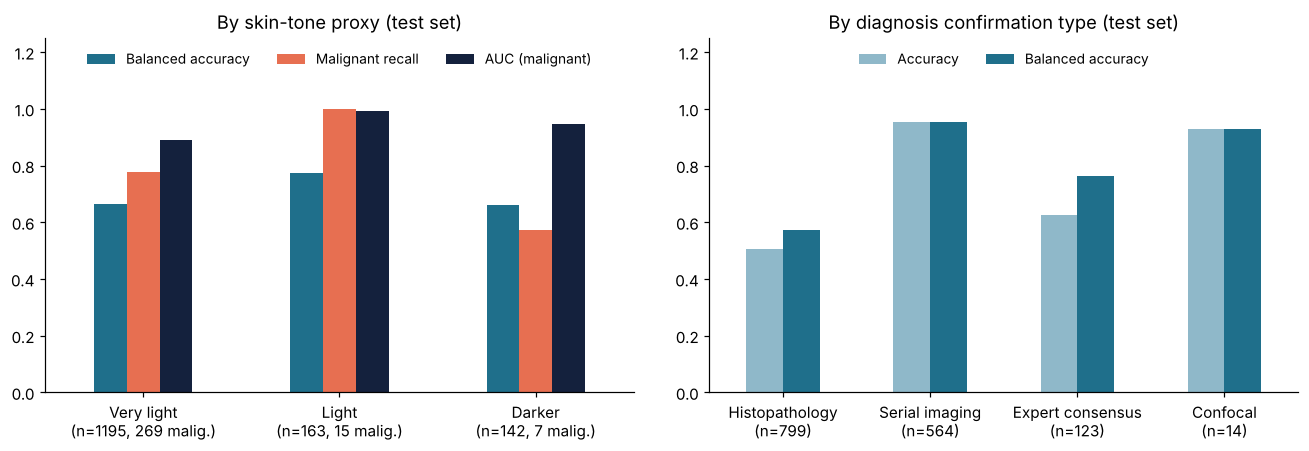

In [12]:
def group_table(col):
    out = []
    for g, d in meta.iloc[te].groupby(col, observed=True):
        ii = np.where(meta.iloc[te][col].values == g)[0]
        t, p = yt[ii], P[ii]; mal = np.isin(t, MALIGNANT)
        out.append({col: g, 'n': len(ii), 'malignant': int(mal.sum()), 'accuracy': accuracy_score(t, p.argmax(1)),
                    'balanced_acc': balanced_accuracy_score(t, p.argmax(1)),
                    'malignant_recall': (np.isin(p.argmax(1)[mal], MALIGNANT)).mean() if mal.any() else np.nan,
                    'auc_mal': roc_auc_score(mal, p[:, MALIGNANT].sum(1)) if 0 < mal.sum() < len(ii) else np.nan})
    return pd.DataFrame(out)
tone_tab = group_table('tone'); conf_tab = group_table('diagnosis_confirm_type')
display(tone_tab.round(3)); display(conf_tab.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
tt = tone_tab.set_index('tone').loc[['Very light (>55)', 'Light (41-55)', 'Darker (ITA<=41)']]
tt.index = [f"{g.split(' (')[0]}\n(n={n}, {m} malig.)" for g, n, m in zip(tt.index, tt.n, tt.malignant)]
tt[['balanced_acc', 'malignant_recall', 'auc_mal']].rename(columns={'balanced_acc': 'Balanced accuracy', 'malignant_recall': 'Malignant recall', 'auc_mal': 'AUC (malignant)'}).plot.bar(ax=ax[0], color=[TEAL, ORANGE, NAVY], rot=0)
ax[0].set_ylim(0, 1.25); ax[0].set_title('By skin-tone proxy (test set)'); ax[0].set_xlabel(''); ax[0].legend(ncol=3, loc='upper center', frameon=False, fontsize=9)
short = {'histopathology': 'Histopathology', 'serial imaging showing no change': 'Serial imaging', 'single image expert consensus': 'Expert consensus', 'confocal microscopy with consensus dermoscopy': 'Confocal'}
ct = conf_tab.sort_values('n', ascending=False).set_index('diagnosis_confirm_type')
ct.index = [f"{short.get(g, g)}\n(n={n})" for g, n in zip(ct.index, ct.n)]
ct[['accuracy', 'balanced_acc']].rename(columns={'accuracy': 'Accuracy', 'balanced_acc': 'Balanced accuracy'}).plot.bar(ax=ax[1], color=[ICE, TEAL], rot=0)
ax[1].set_ylim(0, 1.25); ax[1].set_title('By diagnosis confirmation type (test set)'); ax[1].set_xlabel(''); ax[1].legend(ncol=2, loc='upper center', frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_bias.png'); plt.show()

## 6. Sample outputs and embedding visualisation

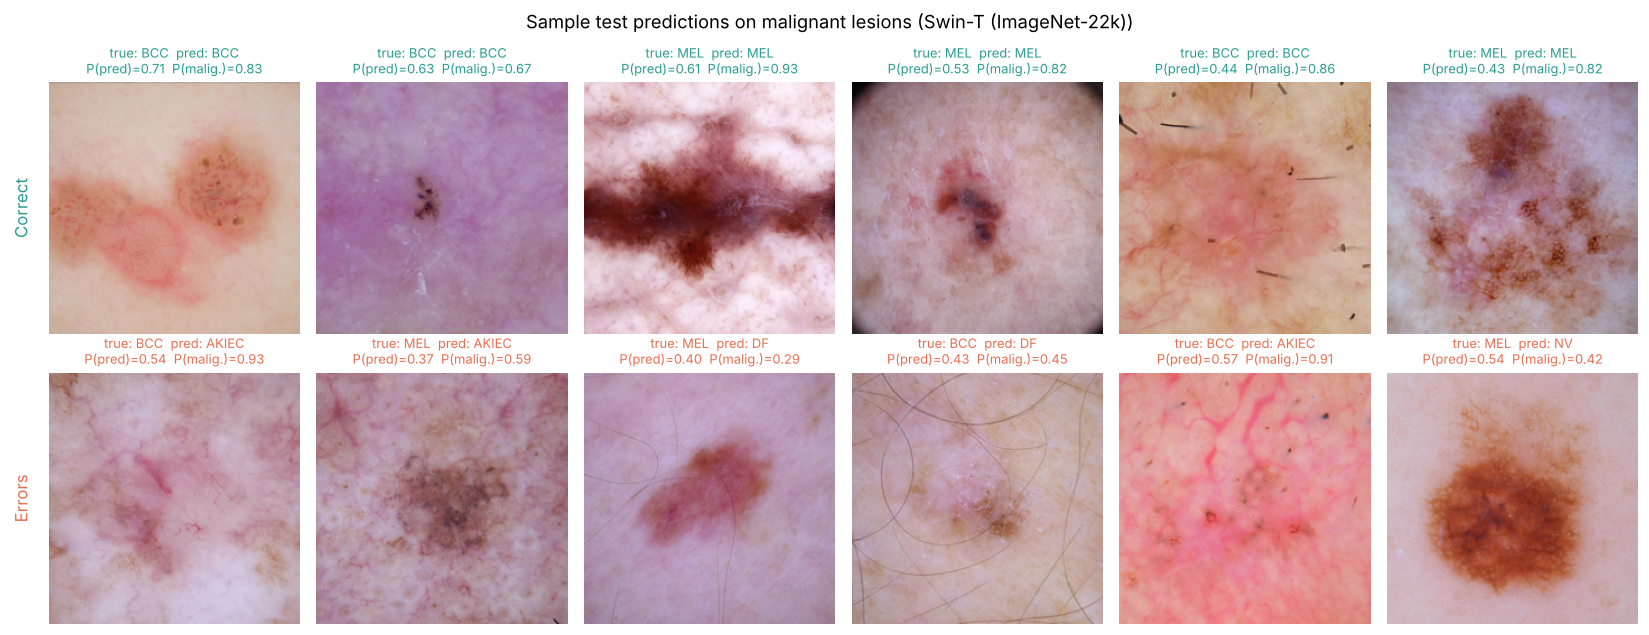

In [13]:
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
r = np.random.default_rng(3)
pick = lambda a: r.choice(a, min(6, len(a)), replace=False)
right = pick(np.where((pred == yt) & np.isin(yt, MALIGNANT))[0])
wrong = pick(np.where((pred != yt) & np.isin(yt, MALIGNANT))[0])
for row, idxs, lab in [(0, right, 'correct'), (1, wrong, 'missed')]:
    for k, i in enumerate(idxs):
        a = axes[row, k]; a.imshow(X[te[i]]); a.axis('off')
        a.set_title(f'true: {CLASSES[yt[i]]}  pred: {CLASSES[pred[i]]}\nP(pred)={P[i].max():.2f}  P(malig.)={P[i, MALIGNANT].sum():.2f}', fontsize=8.5,
                    color=GREEN if row == 0 else ORANGE)
axes[0, 0].text(-0.15, 0.5, 'Correct', transform=axes[0, 0].transAxes, rotation=90, va='center', fontsize=11, color=GREEN)
axes[1, 0].text(-0.15, 0.5, 'Errors', transform=axes[1, 0].transAxes, rotation=90, va='center', fontsize=11, color=ORANGE)
plt.suptitle(f'Sample test predictions on malignant lesions ({BEST})'); plt.tight_layout(); plt.savefig(f'{OUT}/fig_predictions.png'); plt.show()

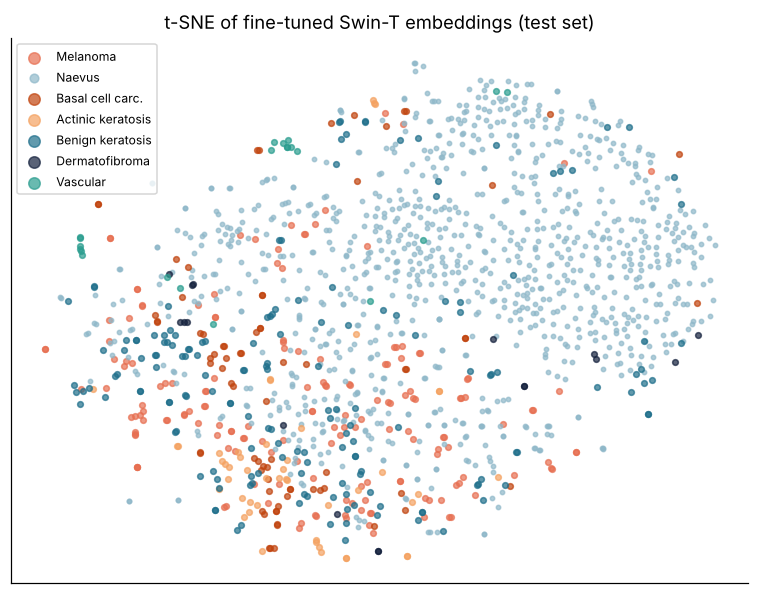

In [14]:
Z = TSNE(n_components=2, perplexity=30, init='pca', random_state=0).fit_transform(RUNS[BEST]['emb_test'])
pal = [ORANGE, ICE, '#C1440E', '#F4A261', TEAL, NAVY, GREEN]
plt.figure(figsize=(7, 5.5))
for c in range(7):
    s = yt == c; plt.scatter(Z[s, 0], Z[s, 1], s=8 if c == 1 else 14, c=pal[c], label=NAMES[c], alpha=.7)
plt.legend(markerscale=2, fontsize=8); plt.title('t-SNE of fine-tuned Swin-T embeddings (test set)'); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.savefig(f'{OUT}/fig_tsne.png'); plt.show()

In [15]:
summary = dict(best=BEST, results=res.to_dict(orient='records'), per_class_recall=rec.to_dict(),
               report=classification_report(yt, pred, target_names=NAMES, output_dict=True),
               tone=tone_tab.to_dict(orient='records'), confirm=conf_tab.to_dict(orient='records'),
               history={k: v['hist'].to_dict(orient='records') for k, v in RUNS.items()},
               split=meta.split.value_counts().to_dict(), tone_counts=meta.tone.value_counts().to_dict(),
               n_lesions=int(meta.lesion_id.nunique()))
json.dump(summary, open(f'{OUT}/results.json', 'w'), indent=1, default=float); print('saved')

saved


## 7. Notes
* All numbers come from a single seed. Future work: full fine-tuning with image-level augmentation and five seeds.
* The ITA skin-tone proxy is computed from dermoscopic border pixels and is only an approximation of skin type; it is used to flag possible bias, not to make clinical claims.